In [13]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import astropy.units as u
import astropy
from astropy.table import Table
from astropy.io import fits
from astropy.io.misc.hdf5 import write_table_hdf5
import os

import Lovell2023_evs as evs
from Lovell2023_stats import compute_conf_ints, eddington_bias
from Lovell2023_stellar import apply_fs_distribution

DATA_PRODUCTS_PATH = 'raid/scratch/work/alberttg/Masters_project/Data_products'

In [14]:
"""
with fits.open('/raid/scratch/work/alberttg/Masters_project/Data_products/First_sample_table.fits') as hdu:

    sample_table = hdu[1].data
sample_table = Table(sample_table)

sample_table.write('sample_table.h5', format='hdf5', overwrite=True)
"""


"\nwith fits.open('/raid/scratch/work/alberttg/Masters_project/Data_products/First_sample_table.fits') as hdu:\n\n    sample_table = hdu[1].data\nsample_table = Table(sample_table)\n\nsample_table.write('sample_table.h5', format='hdf5', overwrite=True)\n"

In [15]:
with h5py.File('/raid/scratch/work/alberttg/Masters_project/Data_products/evs_pdf','r') as hf:
    log10m = hf['log10m'][:]
    f = hf['f'][:]
    F = hf['F'][:]
    N = hf['N'][:]
    z = hf['z'][:]
    

whole_sky = (41252.96 * u.deg**2).to(u.arcmin**2)
survey_area = 90 * u.arcmin**2
fsky = float(survey_area / whole_sky)
phi_max = evs._apply_fsky(N, f, F, fsky)

/tmp/ipykernel_468851/1861089081.py:22: UserWarning: Mismatched number of handles and labels: len(handles) = 5 len(labels) = 4
  leg = ax.legend(handles=[line4,line_dummy,line3,line2,line1],


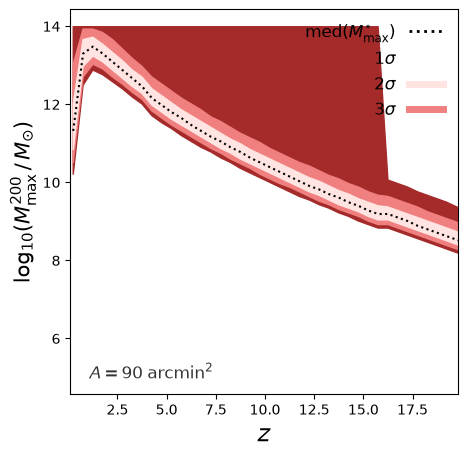

In [16]:
CI_mhalo = compute_conf_ints(phi_max, log10m)

colors = ['brown','lightcoral','mistyrose']

fig, ax = plt.subplots(1, 1, figsize=(5,5))

ax.fill_between(z, CI_mhalo[:,0], CI_mhalo[:,6], alpha=1, color=colors[0])
ax.fill_between(z, CI_mhalo[:,1], CI_mhalo[:,5], alpha=1, color=colors[1])
ax.fill_between(z, CI_mhalo[:,2], CI_mhalo[:,4], alpha=1, color=colors[2])
ax.plot(z, CI_mhalo[:,3], linestyle='dotted', c='black')

ax.set_xlim(0.1, 19.8);
ax.set_xlabel('$z$', size=17)
ax.set_ylabel('$\mathrm{log_{10}}(M^{200}_{\mathrm{max}} \,/\, M_{\odot})$', size=15)
ax.text(0.05, 0.04, '$A = 90 \; \mathrm{arcmin}^2$', size=12, color='black', alpha=0.8, transform = ax.transAxes)

line1 = plt.Line2D((0,1),(0,0), color=colors[0], linewidth=5)
line2 = plt.Line2D((0,1),(0,0), color=colors[1], linewidth=5)
line3 = plt.Line2D((0,1),(0,0), color=colors[2], linewidth=5)
line4 = plt.Line2D((0,1),(0,0), color='black', linestyle='dotted', linewidth=2)
line_dummy = plt.Line2D((0,1),(0,0), color='white')
leg = ax.legend(handles=[line4,line_dummy,line3,line2,line1], 
           labels=['$\mathrm{med}(M^{\star}_{\mathrm{max}})$',
               '$1\sigma$', '$2\sigma$', '$3\sigma$'],
                frameon=False, loc='upper right', fontsize=12, ncol=1)

vp = leg._legend_box._children[-1]._children[0] 
for c in vp._children: c._children.reverse() 
vp.align="right" 

In [17]:
f_b = 0.16
CI_baryon = np.log10(10**CI_mhalo * f_b)

_N = int(1e4)
mstar_pdf = np.vstack([apply_fs_distribution(_phi_max, log10m, _N=_N, method='lognormal') \
        for _phi_max in phi_max])

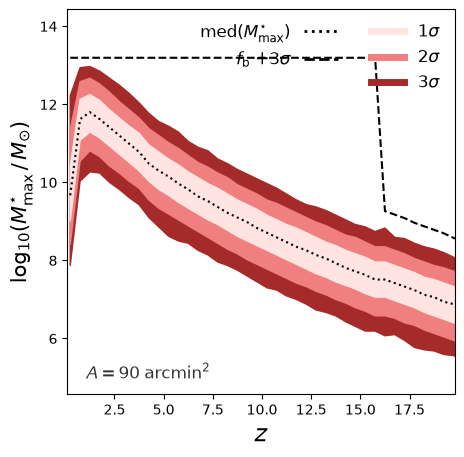

In [18]:
CIs = compute_conf_ints(mstar_pdf, log10m)

fig, ax = plt.subplots(1, 1, figsize=(5,5))

colors = ['brown','lightcoral','mistyrose']

ax.fill_between(z, CIs[:,0], CIs[:,6], alpha=1, color=colors[0])
ax.fill_between(z, CIs[:,1], CIs[:,5], alpha=1, color=colors[1])
ax.fill_between(z, CIs[:,2], CIs[:,4], alpha=1, color=colors[2])
ax.plot(z, CIs[:,3], linestyle='dotted', c='black')
ax.plot(z, CI_baryon[:,6], linestyle='dashed', color='black')

ax.set_xlim(0.1, 19.8); 
# ax.set_ylim(5.4, 11.8)
ax.set_xlabel('$z$', size=17)
ax.set_ylabel('$\mathrm{log_{10}}(M^{\star}_{\mathrm{max}} \,/\, M_{\odot})$', size=15)
ax.text(0.05, 0.04, '$A = 90 \; \mathrm{arcmin}^2$', size=12, color='black', alpha=0.8, transform = ax.transAxes)

line1 = plt.Line2D((0,1),(0,0), color=colors[0], linewidth=5)
line2 = plt.Line2D((0,1),(0,0), color=colors[1], linewidth=5)
line3 = plt.Line2D((0,1),(0,0), color=colors[2], linewidth=5)
line4 = plt.Line2D((0,1),(0,0), color='black', linestyle='dotted', linewidth=2)
line5 = plt.Line2D((0,1),(0,0), color='black', linestyle='dashed', linewidth=2)
line_dummy = plt.Line2D((0,1),(0,0), color='white')
leg = ax.legend(handles=[line4,line5,line_dummy,line3,line2,line1], 
           labels=['$\mathrm{med}(M^{\star}_{\mathrm{max}})$','$f_{\mathrm{b}}$ $+3\sigma$','',
               '$1\sigma$', '$2\sigma$', '$3\sigma$'],
                frameon=False, loc='upper right', fontsize=12, ncol=2)

vp = leg._legend_box._children[-1]._children[0] 
for c in vp._children: c._children.reverse() 
vp.align="right" 